In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!wget -q -O PBC.zip "https://data.mendeley.com/public-files/datasets/snkd93bnjr/files/2fc38728-2ae7-4a62-a857-032af82334c3/file_downloaded"

!rm -rf data/PBC_dataset_normal_DIB
!rm -rf data/__MACOSX
!mkdir -p data

!unzip -q PBC.zip -x "__MACOSX/*" -d data/

In [3]:
import os

bad_file = "data/PBC_dataset_normal_DIB/neutrophil/.DS_169665.jpg"

if os.path.exists(bad_file):
    os.remove(bad_file)

print("Invalid file removed:", not os.path.exists(bad_file))

Invalid file removed: True


In [4]:
csv_file = "/content/drive/MyDrive/Hemavision/pbc_master_split.csv"
dataset_root = "data/PBC_dataset_normal_DIB"

In [5]:
import pandas as pd

df = pd.read_csv(csv_file)

print(df.shape)
print(df["split"].value_counts())
print(df.head())

(17092, 4)
split
train    11964
val       2564
test      2564
Name: count, dtype: int64
                     file_path  label_idx  split    class_name
0    neutrophil/BNE_297581.jpg          6  train    neutrophil
1  erythroblast/ERB_560016.jpg          2  train  erythroblast
2       basophil/BA_547170.jpg          0  train      basophil
3            ig/MMY_913911.jpg          3  train            ig
4       basophil/BA_515691.jpg          0  train      basophil


In [6]:
import os
from PIL import Image
from torch.utils.data import Dataset

class PBCDataset(Dataset):
    def __init__(self, dataframe, dataset_root, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.dataset_root = dataset_root
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = os.path.join(
            self.dataset_root,
            row["file_path"]
        )

        image = Image.open(image_path).convert("RGB")
        label = int(row["label_idx"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [7]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [8]:
train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]
test_df = df[df["split"] == "test"]

print(len(train_df), len(val_df), len(test_df))

11964 2564 2564


In [9]:
train_dataset = PBCDataset(
    train_df,
    dataset_root,
    transform=train_transform
)

val_dataset = PBCDataset(
    val_df,
    dataset_root,
    transform=eval_transform
)

test_dataset = PBCDataset(
    test_df,
    dataset_root,
    transform=eval_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 11964
Validation: 2564
Test: 2564


In [10]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

In [11]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 8 labels:", labels[:8])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 8 labels: tensor([1, 6, 0, 7, 4, 6, 5, 3])


In [12]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [13]:
class_names = (
    df[["label_idx", "class_name"]]
    .drop_duplicates()
    .sort_values("label_idx")["class_name"]
    .tolist()
)

num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Classes: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Number of classes: 8


In [14]:
weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model = model.to(device)

print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 179MB/s]


Linear(in_features=512, out_features=8, bias=True)


In [15]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr = 1e-4,
    weight_decay = 1e-4
)

num_epochs = 10

print("Loss: CrossEntropyLoss")
print("Optimizer: AdamW")
print("Learning rate:", 1e-4)
print("Epochs:", num_epochs)

Loss: CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.0001
Epochs: 10


In [16]:
checkpoint_path = (
    "/content/drive/MyDrive/Hemavision/"
    "hemavision_resnet18_v1_best.pth"
)

print("Best model will be saved to:")
print(checkpoint_path)

Best model will be saved to:
/content/drive/MyDrive/Hemavision/hemavision_resnet18_v1_best.pth


In [17]:
import os

# 1. Verify numeric label to class name mapping
label_mapping = (
    df[["label_idx", "class_name"]]
    .drop_duplicates()
    .sort_values("label_idx")
)
print("Verified Label Mapping:")
print(label_mapping.to_string(index=False))

# 2. Ensure Google Drive checkpoint directory exists
os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)
print("\nCheckpoint folder ready:", os.path.dirname(checkpoint_path))

Verified Label Mapping:
 label_idx   class_name
         0     basophil
         1   eosinophil
         2 erythroblast
         3           ig
         4   lymphocyte
         5     monocyte
         6   neutrophil
         7     platelet

Checkpoint folder ready: /content/drive/MyDrive/Hemavision


In [18]:
import time

best_val_accuracy = 0.0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

print("Starting Model v1 training...")

start_time = time.time()

for epoch in range(num_epochs):

    epoch_start = time.time()

    # TRAINING
    model.train()

    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()


    train_loss = running_train_loss / train_total
    train_accuracy = train_correct / train_total

    # VALIDATION
    model.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()


    val_loss = running_val_loss / val_total
    val_accuracy = val_correct / val_total

    # RECORD RESULTS
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_accuracy)
    history["val_acc"].append(val_accuracy)


    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch+1:02d}/{num_epochs:02d} "
        f"[{epoch_time:.0f}s] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy*100:.2f}%"
    )

    # SAVE BEST MODEL
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "val_accuracy": best_val_accuracy,
            "class_names": class_names
        }, checkpoint_path)

        print(
            f"  --> Saved new best model "
            f"(Val Acc: {best_val_accuracy*100:.2f}%)"
        )


total_time = (time.time() - start_time) / 60

print()
print(f"Training complete in {total_time:.1f} minutes")
print(f"Best validation accuracy: {best_val_accuracy*100:.2f}%")

Starting Model v1 training...
Epoch 01/10 [49s] | Train Loss: 0.2078 | Train Acc: 93.29% | Val Loss: 0.0636 | Val Acc: 97.54%
  --> Saved new best model (Val Acc: 97.54%)
Epoch 02/10 [47s] | Train Loss: 0.0669 | Train Acc: 97.86% | Val Loss: 0.0529 | Val Acc: 98.28%
  --> Saved new best model (Val Acc: 98.28%)
Epoch 03/10 [51s] | Train Loss: 0.0524 | Train Acc: 98.25% | Val Loss: 0.0539 | Val Acc: 98.09%
Epoch 04/10 [50s] | Train Loss: 0.0394 | Train Acc: 98.70% | Val Loss: 0.0483 | Val Acc: 98.44%
  --> Saved new best model (Val Acc: 98.44%)
Epoch 05/10 [51s] | Train Loss: 0.0340 | Train Acc: 98.92% | Val Loss: 0.0459 | Val Acc: 98.63%
  --> Saved new best model (Val Acc: 98.63%)
Epoch 06/10 [51s] | Train Loss: 0.0301 | Train Acc: 99.01% | Val Loss: 0.0344 | Val Acc: 98.83%
  --> Saved new best model (Val Acc: 98.83%)
Epoch 07/10 [51s] | Train Loss: 0.0315 | Train Acc: 98.93% | Val Loss: 0.0481 | Val Acc: 98.60%
Epoch 08/10 [51s] | Train Loss: 0.0261 | Train Acc: 99.07% | Val Loss: 0.

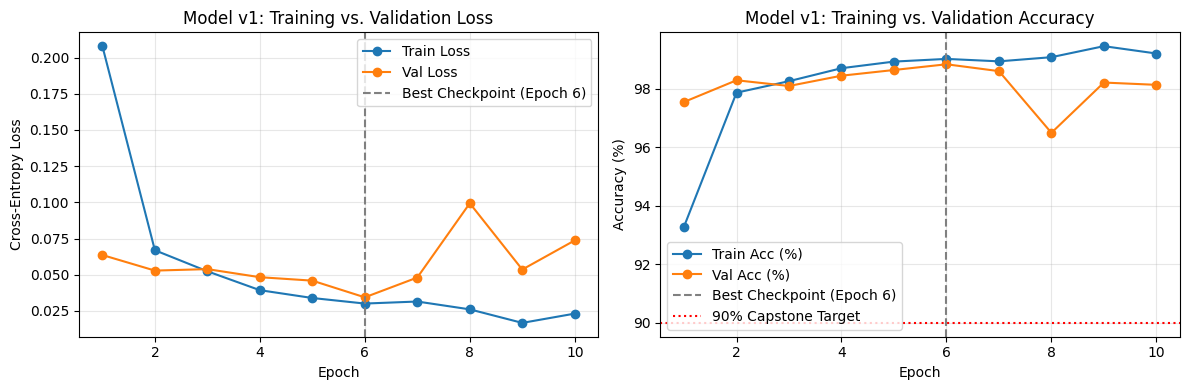

In [19]:
import matplotlib.pyplot as plt

epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(12, 4))

# 1. Loss Curve
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], label="Train Loss", marker="o")
plt.plot(epochs_range, history["val_loss"], label="Val Loss", marker="o")
plt.axvline(x=6, color="gray", linestyle="--", label="Best Checkpoint (Epoch 6)")
plt.title("Model v1: Training vs. Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)

# 2. Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(epochs_range, [a * 100 for a in history["train_acc"]], label="Train Acc (%)", marker="o")
plt.plot(epochs_range, [a * 100 for a in history["val_acc"]], label="Val Acc (%)", marker="o")
plt.axvline(x=6, color="gray", linestyle="--", label="Best Checkpoint (Epoch 6)")
plt.axhline(y=90, color="red", linestyle=":", label="90% Capstone Target")
plt.title("Model v1: Training vs. Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Hemavision/model_v1_training_curves.png", dpi=300)
plt.show()

In [20]:
# Load the best saved Model v1 checkpoint

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

class_names = checkpoint["class_names"]

print("Loaded Model v1 checkpoint")
print("Best epoch:", checkpoint["epoch"])
print(
    "Validation accuracy:",
    f"{checkpoint['val_accuracy'] * 100:.2f}%"
)
print("Classes:", class_names)

Loaded Model v1 checkpoint
Best epoch: 6
Validation accuracy: 98.83%
Classes: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']


In [21]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

test_correct = 0
test_total = 0
running_test_loss = 0.0

all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        running_test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())


test_loss = running_test_loss / test_total
test_accuracy = test_correct / test_total

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

Test Loss: 0.0424
Test Accuracy: 98.67%


In [23]:
print("Classification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        digits=4
    )
)

Classification Report:

              precision    recall  f1-score   support

    basophil     1.0000    0.9945    0.9973       183
  eosinophil     1.0000    1.0000    1.0000       467
erythroblast     0.9831    0.9957    0.9893       233
          ig     0.9636    0.9770    0.9703       434
  lymphocyte     0.9834    0.9780    0.9807       182
    monocyte     0.9680    0.9953    0.9815       213
  neutrophil     0.9918    0.9700    0.9808       500
    platelet     1.0000    0.9943    0.9972       352

    accuracy                         0.9867      2564
   macro avg     0.9862    0.9881    0.9871      2564
weighted avg     0.9869    0.9867    0.9868      2564



In [24]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=range(len(class_names))
)

print("Per-Class Accuracy:\n")

for i, class_name in enumerate(class_names):

  correct = cm[i, i]
  total = cm[i].sum()

  accuracy = correct / total

  print(
      f"{class_name:<15}"
      f"{accuracy * 100:.2f}%"
      f"({correct}/{total})"
  )

Per-Class Accuracy:

basophil       99.45%(182/183)
eosinophil     100.00%(467/467)
erythroblast   99.57%(232/233)
ig             97.70%(424/434)
lymphocyte     97.80%(178/182)
monocyte       99.53%(212/213)
neutrophil     97.00%(485/500)
platelet       99.43%(350/352)


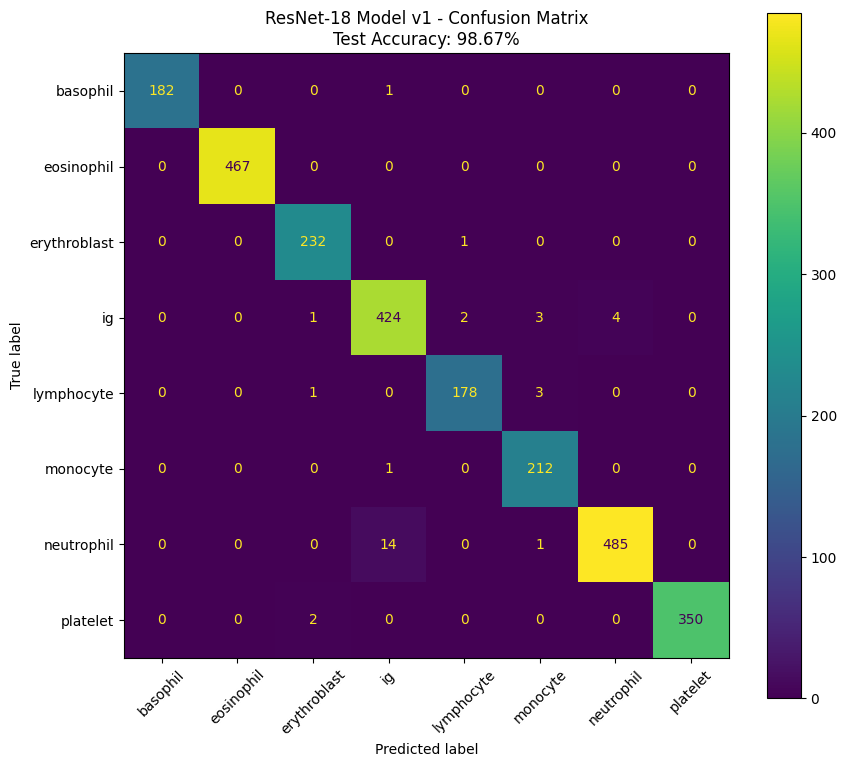

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(9, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

plt.title(
    f"ResNet-18 Model v1 - Confusion Matrix\n"
    f"Test Accuracy: {test_accuracy*100:.2f}%"
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/Hemavision/"
    "model_v1_test_confusion_matrix.png",
    dpi=300
)

plt.show()

In [26]:
import torch
import torch.nn.functional as F
from PIL import Image

def predict_single_image(image_path, model, transform, class_names, device):
    """
    Run Model v1 inference on one image.

    Returns:
        predicted class
        top class probability (%)
        probabilities for all 8 classes
        transformed input tensor
        original RGB image
    """

    image = Image.open(image_path).convert("RGB")

    input_tensor = (
        transform(image)
        .unsqueeze(0)
        .to(device)
    )

    model.eval()

    with torch.no_grad():
        logits = model(input_tensor)
        probs = F.softmax(logits, dim=1)[0]

    pred_idx = int(torch.argmax(probs).item())
    pred_class = class_names[pred_idx]
    top_probability = float(probs[pred_idx].item()) * 100

    prob_dict = {
        class_name: round(float(prob.item()) * 100, 2)
        for class_name, prob in zip(class_names, probs)
    }

    return (
        pred_class,
        round(top_probability, 2),
        prob_dict,
        input_tensor,
        image
    )

In [27]:
sample_row = test_df.iloc[0]

sample_path = os.path.join(
    dataset_root,
    sample_row["file_path"]
)

pred_class, top_prob, prob_dict, input_tensor, raw_img = predict_single_image(
    sample_path,
    model,
    eval_transform,
    class_names,
    device
)

print(f"Sample File:     {sample_row['file_path']}")
print(f"True Class:      {sample_row['class_name']}")
print(f"Predicted Class: {pred_class} ({top_prob:.2f}%)")

print("\nClass Probabilities (%):")

for class_name, probability in prob_dict.items():
    print(f"  {class_name:<15}: {probability:.2f}%")

Sample File:     basophil/BA_241069.jpg
True Class:      basophil
Predicted Class: basophil (100.00%)

Class Probabilities (%):
  basophil       : 100.00%
  eosinophil     : 0.00%
  erythroblast   : 0.00%
  ig             : 0.00%
  lymphocyte     : 0.00%
  monocyte       : 0.00%
  neutrophil     : 0.00%
  platelet       : 0.00%


In [29]:
with torch.no_grad():
    logits = model(input_tensor)
    probs = F.softmax(logits, dim=1)[0]

for cls_name, p in zip(class_names, probs):
    print(f"{cls_name:<15}: {p.item()*100:.8f}%")

print("Total:", probs.sum().item())

basophil       : 99.99905825%
eosinophil     : 0.00005686%
erythroblast   : 0.00010886%
ig             : 0.00004506%
lymphocyte     : 0.00013526%
monocyte       : 0.00002570%
neutrophil     : 0.00056049%
platelet       : 0.00001968%
Total: 1.0000001192092896
